# Evaluation system for SGR recommendations engine

The evaluation uses the external Steam recommendations dataset, prepared by `src/data_analysis/system_evaluation/prepare_evaluation_data.ipynb`. The prepared file `data/external/recommendations_ready.json` maps each user to the games they marked as recommended, split into an input history and a held-out target:

```json
{"<user_id>": {"history": [app_id, app_id, ...], "target": app_id}, ...}
```

- `history`: the user's liked games without the most recent one, oldest first (3 to 9 games)
- `target`: the most recent liked game

The dataset contains only users with 4 to 10 liked games (both inclusive), and only games that have a feature vector in `data/parquet/games_fully_vectorized.parquet`. That means the recommender can score every game in both `history` and `target`.

## Evaluation method

### Protocol: chronological leave-one-out

For each evaluated user:

1. Take the user's `history` as input. The most recent game has already been held out as `target`, which follows real use: we predict the next game a user will like from the games they liked before.
2. Pass `history` to the recommender as `{app_id: 10 for app_id in history}`. The dataset only records whether a user liked a game (yes/no), so every game gets the same weight. `recommend()` divides ratings by 10, so each game has weight 1.
3. Ask for the top `K_MAX = 20` recommendations among the games that were already available on the day the user reviewed `target` (see *Only games released before the target* below). The recommender already excludes the input games.
4. Record the rank of `target` in that list (1 to 20), or "not found".

Every metric below is computed from these ranks, so the recommender runs only once per user.

### Only games released before the target

The reviews end on 2022-12-31, but about 63k of the 155k games in the catalog came out in 2023 or later, and about 34k more have no release date yet (e.g. "Coming soon"). Without a filter, the recommender could fill its top K with these games, and none of them can ever be a `target`. That would lower HR for reasons that have nothing to do with recommendation quality.

So every method only recommends games that were available on the day the user reviewed the `target`. A game's `available_from` date comes from `data/external/release_dates.parquet`, built by `prepare_release_dates.py`. It is the earlier of two dates:

- the Steam release date
- the game's first review in `recommendations.csv`, which catches early access games that got reviews years before their official release

Games with neither date are never recommended. The `target` is always available, because its own review is one of the game's reviews.

### Metrics

| Metric | Definition | Why |
|---|---|---|
| **HR@K** (hit rate) | Share of users whose `target` is in the top K | Main metric: did we suggest the game the user liked next? |
| **MRR@20** (mean reciprocal rank) | Average of `1 / rank`, with 0 when not found | HR treats rank 1 and rank 20 the same; MRR rewards finding the game higher up |
| **Catalog coverage@K** | Share of all games that appear in at least one user's top K | Shows whether the system recommends many different games or the same few to everyone |

HR is reported for K = 5, 10, 15 and 20. K = 15 matches the app, where the API's default `limit` is 15.

### Baselines

A metric on its own can't be interpreted, so the same protocol is run on two baselines:

- **Random:** picks K games at random from the games available at the target's date. Expected HR@K ≈ K / (number of available games), averaged over users. This is the floor.
- **Most popular:** recommends the K available games liked by the most users, skipping games already in the user's history. Popularity is counted from likes dated strictly before the user's `target` date, so the baseline can't use reviews written later (or the user's own target). This is the baseline the recommender really needs to beat: on Steam data, most held-out games are popular ones.

### Sampling and uncertainty

- Evaluate a random 5 samples of `N_USERS = 2_000` users with a fixed seeds, so results can be reproduced. Running all 1.65M users isn't needed for a stable estimate. Each SGR score multiplies the full 155k × 4,100 feature matrix by the profile.
- Report a 95% bootstrap confidence interval for HR@K and MRR (1,000 resamples of users). All methods are scored on the same users, so to compare two of them, bootstrap the *difference* in their scores (a paired bootstrap): if its interval excludes 0, the difference is real.
- For speed, user profiles are scored in batches (`profiles @ matrix.T`), which reads the matrix once per batch instead of once per user. The batched scores must reproduce `recommend()` exactly: the same normalisation, the same weighting and the same exclusion of input games. The notebook checks this on 20 users before the evaluation.

### Breakdowns

Report HR@20 for the recommender and the popularity baseline separately by:

- **History length** (3 to 9 games): does more input help, or does averaging more games blur the profile?
- **Target popularity** (quartiles of users per game): does the recommender only find well-known games, or does it do better than popularity on niche games? A content-based recommender is often expected to help with the long tail, even if it loses on overall HR.

### Known limitations

- **Positive-only data:** a game the user never reviewed isn't necessarily one they dislike, so a recommendation counted as a miss may still be a good one. HR is a lower bound on real quality and is most useful for comparing variants and baselines, not as an absolute score.
- **Easy hits from franchises and editions:** a target like *Dark Souls III* is easy to find when *Dark Souls II* is in the history. Such hits inflate HR compared with genuine discovery.
- **Popularity uses only earlier likes:** an all-time count would include reviews written after the target and makes popular games look more popular than they were then (on 20,000 users it raised most-popular HR@15 from 4.96% to 5.58%), so both the baseline and the boost count only likes from before the target date.
- **Time leakage in features:** game features (e.g. `recommendations`, the review count) reflect the time the data was collected, not the time of the review. Games released after the `target` was reviewed are filtered out (see above), but the features themselves are still from today, so results aren't a strict "what we would have known then" test.
- **Only one target per user:** each user contributes a single held-out game, so per-user results are noisy. The sample size and bootstrap intervals account for this.

## Prototype: evaluation on 2,000 users batch

A first, simple version of the protocol above: HR@K for the SGR recommender and two baselines (random and most popular) on a sample of `N_USERS` users. MRR, coverage, confidence intervals and breakdowns are left for later.

### 1. Load the data and sample users

In [1]:
import json
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, "../../backend")
import cosine_similarity as cs
from cosine_similarity import recommend

DATA_PATH = Path("../../../data/external/recommendations_ready.json")
REVIEWS_PATH = Path("../../../data/external/recommendations.csv")
RELEASE_PATH = Path("../../../data/external/release_dates.parquet")
REPORT_PATH = Path("evaluation_report.txt")

N_USERS = 2000
SEED = 50
KS = [5, 10, 15, 20]
K_MAX = max(KS)

with open(DATA_PATH) as f:
    users = json.load(f)

random.seed(SEED)
sample = random.sample(list(users), N_USERS)
print(f"{len(users):,} users in the dataset, {N_USERS:,} sampled")

1,652,783 users in the dataset, 2,000 sampled


### 2. Target dates and available games

The target's date is the date of the user's review of it. `recommendations_ready.json` stores only app ids, so the date is looked up in `recommendations.csv` with the same filtering as the preparation notebook: positive reviews only, the first review of each user–game pair, only users and games of the prepared dataset. These dated likes (`liked`) are also kept for step 3, which counts popularity from them. The cell checks that they are exactly the likes in `recommendations_ready.json`.

`avail` holds every game's `available_from` date, in the same row order as the feature matrix. Games without any date get `9999-12-31`, so they are never available. A game can be recommended to a user if `avail <= target date`.

This cell also loads the feature matrix (~2.5 GB), so it takes a while.

In [ ]:
cs._load_data_if_needed()
catalog = cs._appids  # every game with a feature vector, in the matrix's row order

available_from = pd.read_parquet(RELEASE_PATH)["available_from"]
# games without any date are never available; some games have placeholder dates like 6969,
# so dates stay in microseconds, which (unlike nanoseconds) can hold them. The sentinel is set
# in numpy, because pandas < 3 stores dates in nanoseconds and can't hold 9999-12-31.
avail = available_from.reindex(catalog).to_numpy("datetime64[us]")
avail[np.isnat(avail)] = np.datetime64("9999-12-31", "us")
sorted_avail = np.sort(avail)  # counting available games is then a single search

reviews = pd.read_csv(
    REVIEWS_PATH,
    usecols=["app_id", "date", "is_recommended", "user_id"],
    dtype={"app_id": "int32", "is_recommended": "bool", "user_id": "int32"},
    parse_dates=["date"],
)
reviews = reviews[reviews["is_recommended"]].drop_duplicates(["user_id", "app_id"])
# every like in the prepared dataset (history and target games of all its users), with its date;
# step 3 counts popularity from these
dataset_ids = np.array([int(user_id) for user_id in users], dtype=np.int32)
liked = reviews[reviews["user_id"].isin(dataset_ids) & reviews["app_id"].isin(catalog)]
del reviews

sample_ids = [int(user_id) for user_id in sample]
targets = pd.DataFrame({"user_id": sample_ids, "app_id": [users[u]["target"] for u in sample]})
targets = targets.merge(liked[["user_id", "app_id", "date"]], on=["user_id", "app_id"], how="left")
target_dates = targets["date"].to_numpy("datetime64[us]")
target_date = dict(zip(sample, target_dates))
n_available = {u: int(np.searchsorted(sorted_avail, d, side="right")) for u, d in target_date.items()}

target_rows = [cs._appid_to_index[users[u]["target"]] for u in sample]
assert targets["date"].notna().all(), "every target must have a review date"
assert (avail[target_rows] <= target_dates).all(), "every target must be available on its review date"
assert sum(len(user["history"]) + 1 for user in users.values()) == len(liked), "likes must match the prepared dataset"

n_avail = pd.Series(n_available)
print(f"catalog:                    {len(catalog):,} games")
print(f"games without any date:     {available_from.reindex(catalog).isna().sum():,}")
print(f"target dates:               {targets['date'].min().date()} .. {targets['date'].max().date()}")
print(f"available games per user:   min {n_avail.min():,}, median {n_avail.median():,.0f}, max {n_avail.max():,}")

### 3. Recommenders

Every method scores games for a user without using their `target`. It never recommends the history games or games released after the target's date.

- **SGR:** the same scores as `recommend()` in `src/backend/cosine_similarity.py`, but with games that weren't available yet set to `-inf`. Every history game has the same weight, so the profile is a plain mean.
- **SGR (no date filter):** the same scores without the date filter, which is how the app behaves. It shows how much the date filter changes the result.
- **Most popular:** the available games liked by the most dataset users **before the user's target date** (`pop_counts`). Likes from that day on are not counted, so the baseline can't use reviews written after the target, and the user's own target is never counted.
- **Random:** `K_MAX` games picked at random from the games available at the target's date.

SGR doesn't build a top-K list. It computes the target's **rank**: 1 + the number of games that score higher than the target. A hit at K means rank ≤ K. Users are scored in batches of `BATCH_SIZE`: one `profiles @ matrix.T` multiplication per batch reads the 2.5 GB matrix once for the whole batch, instead of once per user, which is about 25 times faster.

The last part of the cell checks on 20 users that, without the date filter, the top `K_MAX` games from these scores are exactly the ones `recommend()` returns.

In [ ]:
BATCH_SIZE = 256


def sgr_scores(user_ids):
    """Cosine similarity between each user's profile and every game, the same scores as recommend() in the backend.

    user_ids: sampled user ids scored together in one matrix multiplication

    Returns an array of shape (len(user_ids), number of games). The user's own history games get -inf.
    """
    histories = [[cs._appid_to_index[app_id] for app_id in users[u]["history"]] for u in user_ids]
    profiles = np.stack([cs._matrix[rows].mean(axis=0) for rows in histories])
    profiles /= np.linalg.norm(profiles, axis=1, keepdims=True)
    scores = profiles @ cs._matrix.T
    for i, rows in enumerate(histories):
        scores[i, rows] = -np.inf  # never recommend the user's own games
    return scores


def mask_unavailable(scores, user_ids):
    """Set the score of every game released after the user's target date to -inf, in place.

    scores:   output of sgr_scores(), one row per user
    user_ids: the same users, in the same order
    """
    dates = np.array([target_date[u] for u in user_ids])
    scores[avail[None, :] > dates[:, None]] = -np.inf


def target_ranks(scores, user_ids):
    """Rank of each user's target: 1 + the number of games that score higher than it.

    scores:   one row of scores per user, e.g. from sgr_scores()
    user_ids: the same users, in the same order
    """
    target_rows = np.array([cs._appid_to_index[users[u]["target"]] for u in user_ids])
    target_scores = scores[np.arange(len(user_ids)), target_rows]
    return 1 + (scores > target_scores[:, None]).sum(axis=1)


# popularity as it was known on each user's target date: the number of dataset users who liked a game
# strictly before that day. Later likes are not counted, so the baseline can't use reviews written after the
# target. The user's own target is never counted (it is liked on the target date, not before).
liked_games = np.sort(liked["app_id"].unique())  # every game liked by anyone, in a fixed order
liked_game_rows = np.array([cs._appid_to_index[int(app_id)] for app_id in liked_games])
like_order = np.argsort(liked["date"].to_numpy("datetime64[us]"), kind="stable")
like_dates = liked["date"].to_numpy("datetime64[us]")[like_order]
like_games = np.searchsorted(liked_games, liked["app_id"].to_numpy())[like_order]  # position in liked_games

pop_counts = {}  # user id -> likes of each game in liked_games before the user's target date
counts = np.zeros(len(liked_games), dtype=np.int32)
counted = 0  # likes already added to counts; users are visited from the earliest target date
for user_id in sorted(sample, key=lambda u: target_date[u]):
    end = int(np.searchsorted(like_dates, target_date[user_id], side="left"))  # likes strictly before that day
    counts += np.bincount(like_games[counted:end], minlength=len(liked_games)).astype(np.int32)
    counted = end
    pop_counts[user_id] = counts.copy()


def popular(history, date, counts):
    """The K_MAX most popular games that are available on the given date and not in the history.

    history: app ids of the games the user liked
    date:    the target's review date
    counts:  likes of each game in liked_games before that date, from pop_counts
    """
    recs = []
    for i in np.argsort(-counts, kind="stable"):
        if counts[i] == 0:
            break  # only games someone liked before the date, as before with every liked game
        if int(liked_games[i]) not in history and avail[liked_game_rows[i]] <= date:
            recs.append(int(liked_games[i]))
            if len(recs) == K_MAX:
                break
    return recs


catalog_by_date = catalog[np.argsort(avail, kind="stable")]  # the first n games are the n available ones

def random_pick(history, date):
    """K_MAX random games that are available on the given date and not in the history.

    history: app ids of the games the user liked
    date:    the target's review date
    """
    n = int(np.searchsorted(sorted_avail, date, side="right"))
    picks = catalog_by_date[random.sample(range(n), K_MAX + len(history))].tolist()
    return [app_id for app_id in picks if app_id not in history][:K_MAX]


# check: without the date filter, the top K_MAX games are the same as the backend's recommend()
check_users = sample[:20]
check_scores = sgr_scores(check_users)
for i, user_id in enumerate(check_users):
    top = catalog[np.argsort(-check_scores[i])[:K_MAX]].tolist()
    backend = [r["appid"] for r in recommend({app_id: 10 for app_id in users[user_id]["history"]}, limit=K_MAX)]
    assert top == backend, user_id
print("sgr_scores() matches recommend() on 20 users")

### 4. Evaluate

Every method gets a rank for every user's `target`. For the baselines it's the target's position in their list, or `inf` if it isn't in it. For SGR it's computed from the scores, as described in step 3. The no-filter and filtered SGR ranks come from the same multiplication: rank first, then mask the unavailable games and rank again.

A hit at K means rank ≤ K, and HR@K is the share of users with a hit.

In [ ]:
names = ["SGR", "SGR (no date filter)", "Most popular", "Random"]
ranks = {name: np.zeros(N_USERS) for name in names}

for start in range(0, N_USERS, BATCH_SIZE):
    batch = sample[start:start + BATCH_SIZE]
    scores = sgr_scores(batch)
    ranks["SGR (no date filter)"][start:start + len(batch)] = target_ranks(scores, batch)
    mask_unavailable(scores, batch)
    ranks["SGR"][start:start + len(batch)] = target_ranks(scores, batch)

for i, user_id in enumerate(sample):
    history = users[user_id]["history"]
    target = users[user_id]["target"]
    date = target_date[user_id]
    for name, recs in [("Most popular", popular(history, date, pop_counts[user_id])),
                       ("Random", random_pick(history, date))]:
        ranks[name][i] = recs.index(target) + 1 if target in recs else np.inf

hits = {name: {k: int((ranks[name] <= k).sum()) for k in KS} for name in names}
hr = {name: {k: hits[name][k] / N_USERS for k in KS} for name in names}
pd.DataFrame(hr).rename(index=lambda k: f"HR@{k}").map(lambda x: f"{x:.2%}")

### 5. Report

The report compares SGR with both baselines as a ratio (*lift*): "3.0x" means SGR finds the target 3 times as often.

With 2,000 users the random baseline almost never hits, so its measured HR is usually 0 and a ratio can't be computed. SGR is therefore compared with the **expected** random hit rate: `K / number of available games`, averaged over users. The measured random HR is still shown as a sanity check.

In [5]:
expected_random = {k: float(np.mean([k / n_available[u] for u in sample])) for k in KS}
short = {"SGR": "SGR", "SGR (no date filter)": "SGR no filter", "Most popular": "Most popular", "Random": "Random"}

def lift(a, b):
    return f"{a / b:,.1f}x" if b > 0 else "n/a (0 hits)"

lines = [
    "SGR recommender evaluation - prototype",
    "",
    f"users evaluated:  {N_USERS:,} (random sample, seed {SEED}, of {len(users):,})",
    f"catalog size:     {len(catalog):,} games, {n_avail.mean():,.0f} on average available at the target date",
    "method:           chronological leave-one-out; the user's history is the input,",
    "                  a hit means the held-out most recent game is in the top K;",
    "                  only games available on the target's review date are recommended",
    "                  (except 'SGR no filter', which scores like the backend's recommend())",
    "",
    "Hit rate (HR@K)",
    f"{'':8}" + "".join(f"{short[n]:>15}" for n in names) + f"{'Random (exp.)':>15}",
]
for k in KS:
    lines.append(f"{f'HR@{k}':8}" + "".join(f"{hr[n][k]:>15.2%}" for n in names) + f"{expected_random[k]:>15.4%}")

lines += ["", "SGR compared with baselines (SGR HR / baseline HR)",
          f"{'':8}{'vs random (expected)':>22}{'vs most popular':>18}"]
for k in KS:
    lines.append(
        f"{f'HR@{k}':8}{lift(hr['SGR'][k], expected_random[k]):>22}"
        f"{lift(hr['SGR'][k], hr['Most popular'][k]):>18}"
    )

lines += ["", "Hits (users with the target in the top K)",
          f"{'':8}" + "".join(f"{short[n]:>15}" for n in names)]
for k in KS:
    lines.append(f"{f'HR@{k}':8}" + "".join(f"{hits[n][k]:>15}" for n in names))

report = "\n".join(lines) + "\n"
REPORT_PATH.write_text(report)
print(report)
print(f"saved to {REPORT_PATH.resolve()}")

SGR recommender evaluation - prototype

users evaluated:  2,000 (random sample, seed 50, of 1,652,783)
catalog size:     155,353 games, 46,037 on average available at the target date
method:           chronological leave-one-out; the user's history is the input,
                  a hit means the held-out most recent game is in the top K;
                  only games available on the target's review date are recommended
                  (except 'SGR no filter', which scores like the backend's recommend())

Hit rate (HR@K)
                    SGR  SGR no filter   Most popular         Random  Random (exp.)
HR@5              1.40%          1.10%          1.80%          0.00%        0.0134%
HR@10             1.80%          1.55%          3.95%          0.00%        0.0268%
HR@15             2.35%          1.90%          5.40%          0.00%        0.0402%
HR@20             3.10%          2.35%          7.00%          0.00%        0.0536%

SGR compared with baselines (SGR HR / baseline HR)


### 6. Plot: hit rate by K

HR@K for each method as K grows, using the results from step 4. SGR without the date filter is drawn in grey for comparison. The random baseline is drawn as a dashed line because it shows the expected value, not a measured one. On this scale it stays close to 0, which is the point: it shows how far both real methods are above chance.

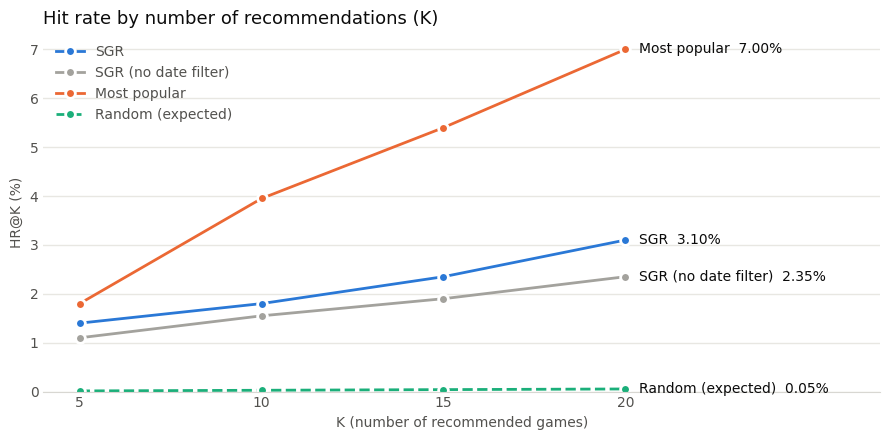

In [6]:
import matplotlib.pyplot as plt

series = {
    "SGR": ([hr["SGR"][k] for k in KS], "#2a78d6", "-"),
    "SGR (no date filter)": ([hr["SGR (no date filter)"][k] for k in KS], "#a3a29d", "-"),
    "Most popular": ([hr["Most popular"][k] for k in KS], "#eb6834", "-"),
    "Random (expected)": ([expected_random[k] for k in KS], "#1baf7a", "--"),
}

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, (values, color, style) in series.items():
    ax.plot(KS, [v * 100 for v in values], style, color=color, linewidth=2,
            marker="o", markersize=7, markeredgecolor="white", markeredgewidth=2, label=name)
    # direct label at the end of each line, in text color
    ax.annotate(f"{name}  {values[-1]:.2%}", xy=(KS[-1], values[-1] * 100),
                xytext=(10, 0), textcoords="offset points", va="center", color="#0b0b0b", fontsize=10)

ax.set_title("Hit rate by number of recommendations (K)", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("K (number of recommended games)", color="#52514e")
ax.set_ylabel("HR@K (%)", color="#52514e")
ax.set_xticks(KS)
ax.set_xlim(KS[0] - 1, KS[-1] + 7)  # room for the direct labels
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e8e7e2", linewidth=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", labelcolor="#52514e")
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()

## Summary of the prototype results

Results for the sample with `SEED = 50` (2,000 users). Every method uses the date filter except the last column, which is SGR as the app runs it.

| | SGR | Most popular | Random (expected) | SGR (no date filter) |
|---|---|---|---|---|
| HR@5 | 1.40% | 1.80% | 0.013% | 1.10% |
| HR@10 | 1.80% | 3.95% | 0.027% | 1.55% |
| HR@15 | 2.35% | 5.40% | 0.040% | 1.90% |
| HR@20 | 3.10% | 7.00% | 0.054% | 2.35% |

### Effect of the date filter

- **Most of the catalog wasn't out yet.** On average only 46,037 of the 155,353 games were available on the target's date (median 48,762). For the oldest target, from 2012, only 1,226 were.
- **SGR gains the most.** HR@20 goes from 2.35% to 3.10% (47 → 62 hits). Without the filter, recent games similar to the history took places in the top 20 that the target could never win. The gain is certain, not noise: removing games can only move the target up, never down, on the same users.
- **Most popular barely changes** (6.85% → 7.00% at K = 20). Popularity is counted from histories, which all end in 2022, so the most popular games are old ones anyway.
- **Random gets a smaller pool.** Its expected HR is about 4 times higher, because it now picks from ~46k games instead of 155k. SGR's lift over random falls from about 180x to 58x. That isn't a worse result, just a fairer comparison.

### What the plot shows

- **Most popular is the highest line at every K** and rises quickly, from 1.80% at K = 5 to 7.00% at K = 20.
- **SGR is clearly above random but well below most popular.** It rises slowly, from 1.40% to 3.10%.
- **Random stays at almost 0.** At K = 20 the expected hit rate is 0.054%, so on this scale its line lies on the axis.
- **The gap between SGR and most popular grows with K.** Popularity gains about 1.7 points per 5 extra games, while SGR gains about 0.6.

### How we interpret it

- **SGR's vectors carry real signal.** It finds the user's next game about 58 times as often as random guessing does at K = 20 (3.10% vs 0.054%). The feature vectors capture something about what users like.
- **The task favours popular games.** A small set of very popular games covers a large share of what users like next: across the whole dataset, 6.5% of the target games are among the top 20 most popular games, and 23.4% are among the top 100. Recommending bestsellers is therefore a strong, easy guess.
- **SGR ignores popularity.** It recommends games *similar* to the history, often niche games with matching tags and descriptions, while users often go on to like a hit. That's why it finds the target less than half as often as the popularity baseline at K = 20.
- **Hit rate doesn't measure everything.** The popularity baseline gives almost every user the same list, which isn't personalised and doesn't help users discover new games. Losing to it on HR doesn't make SGR useless, but it shows that adding popularity to SGR could help. That is tested in the experiment below.
- **Treat the numbers as rough.** At N = 2,000, SGR has only 62 hits at K = 20. Differences under about 1 point between samples are noise. The evaluation now takes about a minute, so a larger sample (e.g. the planned `N_USERS = 50_000`) is cheap.

## Experiment: SGR with a popularity boost

Because most popular beats SGR, we tested whether mixing popularity into SGR's scores helps. Each game's score becomes:

```
score = cosine similarity + ALPHA * popularity
```

- **cosine similarity:** exactly what `recommend()` computes, between the user's profile and the game
- **popularity:** `log(1 + number of users who liked the game)`, scaled to 0–1 so the most popular game gets 1. The log stops a few huge hits from taking over. Counts are the likes before the user's target date, as in the popularity baseline, so the scale is per user.
- **ALPHA:** how strong the boost is. `ALPHA = 0` is plain SGR, and a very large `ALPHA` turns into the most-popular baseline.

This lives only in this notebook; the backend is unchanged. The code reuses `sgr_scores()` and `mask_unavailable()` from step 3, so it applies the same date filter as SGR.

Instead of building a top-20 list for every `ALPHA`, the code computes the target's **rank** directly: 1 + the number of games that score higher than the target. A hit at K means rank ≤ K. Similarities are computed once per batch of users and reused for every `ALPHA`.

In [ ]:
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]


def popularity_scores(user_ids):
    """Popularity of every game on each user's target date, scaled to 0-1, in the matrix's row order.

    user_ids: sampled user ids, e.g. one batch

    Returns an array of shape (len(user_ids), number of games): log(1 + likes before the target date),
    divided by the same value of the most liked game on that date. Games nobody liked yet get 0.
    """
    scores = np.zeros((len(user_ids), len(catalog)), dtype=np.float32)
    for i, user_id in enumerate(user_ids):
        log_counts = np.log1p(pop_counts[user_id])
        if log_counts.max() > 0:
            scores[i, liked_game_rows] = log_counts / log_counts.max()
    return scores


boost_ranks = {alpha: np.zeros(N_USERS) for alpha in ALPHAS}

for start in range(0, N_USERS, BATCH_SIZE):
    batch = sample[start:start + BATCH_SIZE]
    sims = sgr_scores(batch)
    mask_unavailable(sims, batch)
    pop_scores = popularity_scores(batch)
    for alpha in ALPHAS:
        boost_ranks[alpha][start:start + len(batch)] = target_ranks(sims + alpha * pop_scores, batch)

boost_hits = {alpha: {k: int((boost_ranks[alpha] <= k).sum()) for k in KS} for alpha in ALPHAS}
boost_hr = pd.DataFrame(
    {f"SGR, ALPHA={alpha}": {f"HR@{k}": boost_hits[alpha][k] / N_USERS for k in KS} for alpha in ALPHAS}
)
boost_hr["Most popular"] = {f"HR@{k}": hr["Most popular"][k] for k in KS}
boost_hr.map(lambda x: f"{x:.2%}")

`ALPHA = 0` is exactly the same computation as SGR in step 4, so it must give the same numbers.

The table is also appended to the report file.

In [ ]:
boost_lines = ["", "Experiment: SGR + ALPHA * popularity (HR@K)",
               f"{'':8}" + "".join(f"{f'a={alpha}':>9}" for alpha in ALPHAS) + f"{'Popular':>10}"]
for k in KS:
    row = "".join(f"{boost_hits[alpha][k] / N_USERS:>9.2%}" for alpha in ALPHAS)
    boost_lines.append(f"{f'HR@{k}':8}{row}{hr['Most popular'][k]:>10.2%}")

boost_report = "\n".join(boost_lines) + "\n"
with open(REPORT_PATH, "a") as f:
    f.write(boost_report)


Experiment: SGR + ALPHA * popularity (HR@K)
            a=0.0    a=0.2    a=0.4    a=0.6    a=0.8    a=1.0   Popular
HR@5        1.40%    2.75%    3.10%    3.15%    3.20%    3.00%     1.80%
HR@10       1.80%    4.30%    5.10%    5.35%    5.30%    5.55%     3.95%
HR@15       2.35%    5.85%    7.00%    7.55%    7.45%    7.60%     5.40%
HR@20       3.10%    7.00%    8.20%    9.00%    9.40%    9.60%     7.00%



### Results (ALPHA from 0 to 1.0, with the date filter)

The same 2,000 users and protocol as above (`SEED = 50`). The backend was not changed. `ALPHA = 0` reproduces SGR's results exactly (62 hits at K = 20).

| | ALPHA = 0 (SGR) | 0.2 | 0.4 | 0.6 | 0.8 | 1.0 | Most popular |
|---|---|---|---|---|---|---|---|
| HR@5 | 1.40% | 2.75% | 3.10% | 3.15% | **3.20%** | 3.00% | 1.80% |
| HR@10 | 1.80% | 4.30% | 5.10% | 5.35% | 5.30% | **5.55%** | 3.95% |
| HR@15 | 2.35% | 5.85% | 7.00% | 7.55% | 7.45% | **7.60%** | 5.40% |
| HR@20 | 3.10% | 7.00% | 8.20% | 9.00% | 9.40% | **9.60%** | 7.00% |

An earlier run without the date filter (ALPHA from 0 to 0.5) showed the same pattern, with HR@20 rising from 2.35% to 8.30%.

### Interpretation

- **The boost helps a lot.** At `ALPHA = 1.0`, HR@20 goes from 3.10% to 9.60%, about 3 times higher.
- **SGR with the boost beats both methods on their own.** From `ALPHA = 0.2` up it is at or above most popular at every K. Similarity and popularity carry different information, and combining them works better than either one alone.
- **The curve flattens above `ALPHA = 0.6`.** HR@20 still rises slightly, but HR@5 to HR@15 barely move between 0.6 and 1.0, and HR@5 drops a little at 1.0. For K = 15, the app's default, 0.6 and 1.0 differ by one hit, so at N = 2,000 these values can't be told apart.

### Hit rate across a fine ALPHA grid (0 to 2)

The table above only tries 6 values, and HR@20 is still rising at `ALPHA = 1.0`. To see where the curve peaks, the same computation is repeated for `ALPHA` from 0 to 2 in steps of 0.05, on the same users. Each line is one HR@K, and the dot marks its highest point.

Each step on a line is one user more or less (0.05 points at N = 2,000), so small wiggles are noise.

In [ ]:
ALPHA_GRID = np.round(np.linspace(0, 2, 41), 2)  # 0.00, 0.05, ..., 2.00

grid_ranks = np.zeros((len(ALPHA_GRID), N_USERS))  # one row of target ranks per ALPHA

for start in range(0, N_USERS, BATCH_SIZE):
    batch = sample[start:start + BATCH_SIZE]
    sims = sgr_scores(batch)
    mask_unavailable(sims, batch)
    pop_scores = popularity_scores(batch)
    for i, alpha in enumerate(ALPHA_GRID):
        grid_ranks[i, start:start + len(batch)] = target_ranks(sims + alpha * pop_scores, batch)

# HR@K for every ALPHA: rows are ALPHA values, columns are K
grid_hr = pd.DataFrame(
    {f"HR@{k}": (grid_ranks <= k).mean(axis=1) for k in KS},
    index=pd.Index(ALPHA_GRID, name="ALPHA"),
)

best = pd.DataFrame({
    "best ALPHA": grid_hr.idxmax(),
    "HR at best": grid_hr.max().map(lambda x: f"{x:.2%}"),
    "HR at ALPHA=2": grid_hr.iloc[-1].map(lambda x: f"{x:.2%}"),
})
best

In [ ]:
# one blue per K, light (small K) to dark (large K)
k_colors = {5: "#86b6ef", 10: "#3987e5", 15: "#1c5cab", 20: "#0d366b"}

fig, ax = plt.subplots(figsize=(9, 4.5))
for k in KS:
    values = grid_hr[f"HR@{k}"] * 100
    ax.plot(ALPHA_GRID, values, "-", color=k_colors[k], linewidth=2, label=f"HR@{k}")
    # dot at the highest point of the line
    peak = values.idxmax()
    ax.plot(peak, values[peak], "o", color=k_colors[k], markersize=8,
            markeredgecolor="white", markeredgewidth=2)
    # direct label at the end of the line, in text color
    ax.annotate(f"HR@{k}  {values.iloc[-1]:.2f}%", xy=(ALPHA_GRID[-1], values.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color="#0b0b0b", fontsize=10)

ax.set_title("Hit rate by popularity boost (ALPHA), dot = best ALPHA", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("ALPHA (strength of the popularity boost)", color="#52514e")
ax.set_ylabel("HR@K (%)", color="#52514e")
ax.set_xlim(0, ALPHA_GRID[-1] + 0.4)  # room for the direct labels
ax.set_xticks(np.arange(0, 2.01, 0.25))
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e8e7e2", linewidth=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower center", ncol=4, labelcolor="#52514e")  # empty area under the lines
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()

## Results across 6 seeds (12,000 users)

To check how much the numbers above depend on the sample, this notebook was run unchanged for 5 more seeds (1, 7, 42, 99, 123) by `run_seeds.py`, which runs this notebook's code cells once per seed. Only `SEED` and the report path change. To repeat it, run `python run_seeds.py` (about 15 minutes); `python run_seeds.py 3 4 5` tests other seeds, and `python run_seeds.py --summary-only` rebuilds the combined report from the saved per-seed results. With `SEED = 50` that makes 6 samples of 2,000 users, 12,000 users in total. Re-running seed 50 reproduced `evaluation_report.txt` exactly.

Reports are in `reports/`: one `evaluation_report_seed<N>.txt` per seed (same format as `evaluation_report.txt`), the raw numbers in `results_seed<N>.json`, each seed's plots in `seed_plots/`, and `evaluation_report_seeds.txt`, which combines all 6. The pooled numbers below count every user of every seed. The intervals are 95% binomial intervals.

Seed 2024 was tried first and replaced by 99 (`run_seeds.py` reports such a seed and leaves it out). The check in step 3 failed on one user, because four games (app ids 1695790–1695795) have exactly the same score and the notebook and `recommend()` list tied games in a different order. The scores themselves matched. HR is not affected, because `target_ranks()` only counts games that score strictly higher than the target.

### Main methods (pooled)

| | SGR | SGR (no date filter) | Most popular | Random (expected) |
|---|---|---|---|---|
| HR@5 | 1.22% [1.02–1.41] | 0.94% | 2.43% [2.15–2.70] | 0.014% |
| HR@10 | 1.80% [1.56–2.04] | 1.39% | 4.37% [4.00–4.73] | 0.027% |
| HR@15 | 2.25% [1.98–2.52] | 1.70% | 5.67% [5.25–6.08] | 0.041% |
| HR@20 | 2.78% [2.49–3.08] | 2.08% | 7.05% [6.59–7.51] | 0.055% |

- **The 2,000-user conclusions hold.** SGR is about 51x above random at K = 20 and about 0.4x of most popular at every K. Seed 50 was one of the better samples for SGR (HR@20 3.10%; across seeds 2.40–3.10%).
- **The date filter helps on every seed and at every K.** HR@20 goes from 2.08% to 2.78% pooled.
- **Most popular varies more between samples** (HR@20 from 6.00% to 7.90%) than SGR (2.40% to 3.10%), so one sample of 2,000 users isn't enough to compare the two methods.
- **The random baseline behaves as expected.** It got 8 hits at K = 20 over 12,000 users, against about 6.5 expected.

### Popularity boost (pooled, ALPHA from 0 to 2)

| | ALPHA = 0 | 0.25 | 0.5 | 0.75 | 1.0 | 1.25 | 1.5 | 2.0 | Most popular |
|---|---|---|---|---|---|---|---|---|---|
| HR@5 | 1.22% | 2.45% | 2.80% | **2.93%** | 2.78% | 2.82% | 2.70% | 2.62% | 2.43% |
| HR@10 | 1.80% | 4.28% | 4.93% | **4.98%** | 4.88% | 4.88% | 4.80% | 4.70% | 4.37% |
| HR@15 | 2.25% | 5.75% | 6.52% | **6.98%** | 6.94% | 6.80% | 6.73% | 6.58% | 5.67% |
| HR@20 | 2.78% | 6.94% | 8.05% | 8.47% | **8.69%** | 8.51% | 8.47% | 8.39% | 7.05% |

![Hit rate by ALPHA, mean of 6 seeds](reports/hr_by_alpha_seeds.png)

- **HR doesn't keep rising with ALPHA.** It climbs steeply up to about 0.5, flattens between about 0.6 and 1.25, then slowly falls. At `ALPHA = 2` every HR@K is below its peak, moving back toward the most-popular baseline. The rise seen up to `ALPHA = 1.0` with seed 50 was the left part of this plateau.
- **The exact peak can't be pinned down.** The best `ALPHA` for each seed is spread out (for HR@20, anywhere from 0.85 to 1.85), and on the pooled curve the plateau varies by less than the sampling noise. Any `ALPHA` from about 0.6 to 1.25 is equally good on this data.
- **The boosted SGR beats most popular.** At `ALPHA` 0.75–1.0 it is about 1.6 points above it at K = 20 (8.69% vs 7.05%, with no overlap between the intervals). At K = 5 the gain is smaller (2.93% vs 2.43%).
- **Choice for the app:** for K = 15 (the API default), `ALPHA = 0.75` scored best (6.98%), and 1.0 is practically the same (6.94%). The best value was picked on the same users it is measured on, so the peak HR is slightly optimistic.